# Fractal subsystem constraints, general form: $L_x \times L_y$ lattice over $\mathbb{Z}_p$

Generalisation of `fractal_constraints_Nc.ipynb`. The six-neighbour operator identity

$$t_{i+e_1}+t_{i-e_1}+t_{i+e_2}+t_{i-e_2}+t_{i+e_1-e_2}+t_{i-e_1+e_2}=0 \pmod p$$

is turned into a linear-algebra problem over $GF(p)$ on a **rectangular** torus $L_x \times L_y$.
Every function below takes `Lx`, `Ly` and the modulus `p` as explicit arguments; the original
notebook is the special case `Lx == Ly`, `p == 2`.

**The logic, unchanged in four steps:**

1. The six-roll-and-sum expression *is* a linear operator $A$ acting on lattice configurations $t$.
2. Feeding $A$ a single-site "delta" tensor returns one **column** of its matrix.
3. Doing that for all $L_x L_y$ sites builds the full matrix.
4. The number of independent operator identities is $N_c = \dim\ker A$ over $GF(p)$.

The ground state degeneracy per plane is then $\mathrm{GSD} = p^{N_c}$ for $\mathbb{Z}_p$ qudits.

**What the two moduli do, previewed:**

| | $p = 2$ | $p = 3$ |
|---|---|---|
| $N_c$ | $L_x + L_y + \gcd(L_x,L_y) - 2$ — smooth, always large | sparse; $N_c = 1$ for most sizes, spikes at special ones |
| character | generic subsystem symmetry | number-theoretic, fractal-like |

So the fractal fingerprint the $p=2$ notebook went looking for in the vertical direction is already
present in-plane — it just needs $\mathbb{Z}_3$ qudits instead of qubits. Section 7 shows the same
sparseness at $p = 5, 7$ too, so it is $p=2$ that is the exceptional, non-fractal case.

**Caveat:** $p$ must be **prime**. The elimination below inverts pivots via Fermat's little theorem
($a^{-1} = a^{p-2}$), which requires a field. For composite $p$ the ring $\mathbb{Z}_p$ has zero
divisors and "dimension of the kernel" is not even the right question — it needs the Smith normal
form instead.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from math import gcd

## 1. The operator: six rolls, summed mod $p$

`torch.roll(t, shift, dim)` sets `new[k] = old[k - shift]`, and it **wraps around** — the periodic
boundary condition, for free. On a rectangular torus the two axes simply wrap with different periods.

**Index convention used throughout:** a configuration is a tensor of shape `(Ly, Lx)`.

- `dim=1` (columns, length $L_x$) is the $e_1$ direction,
- `dim=0` (rows, length $L_y$) is the $e_2$ direction.

The shift list is unchanged from the square case — the *lattice* is still triangular, only the torus
it lives on became rectangular. The two double-rolls sample the **anti-diagonal** pair $(+1,-1)$ and
$(-1,+1)$, i.e. $e_1-e_2$ and $-e_1+e_2$. A square-lattice Laplacian would instead include the
main-diagonal corners $(\pm1,\pm1)$; the triangular lattice has no such bonds.

The only change for general $p$ is the final `% p`: coefficients live in $\mathbb{Z}_p$, so a site
is satisfied when its six neighbours sum to $0 \bmod p$ rather than $0 \bmod 2$.

In [2]:
SHIFTS = [(0, 1), (0, -1), (1, 0), (-1, 0), (-1, 1), (1, -1)]  # (d2, d1) = (row, col)

def six_neighbor_sum(t, p=2):
    '''Apply the six-neighbour constraint operator A to a configuration t, mod p.

    t : tensor of shape (Ly, Lx); axis 0 is e_2, axis 1 is e_1.
    p : modulus (prime).
    '''
    out = torch.zeros_like(t)
    for (d2, d1) in SHIFTS:
        out = out + torch.roll(torch.roll(t, d2, 0), d1, 1)
    return out % p

Lx, Ly = 5, 3
for p in (2, 3):
    rand_t = torch.randint(0, p, (Ly, Lx))
    print(f"--- p = {p},  {Ly} x {Lx} lattice ---")
    print("Random configuration t:\n", rand_t.numpy())
    print("A(t) - nonzero entries mark sites where the constraint is VIOLATED:")
    print(six_neighbor_sum(rand_t, p).numpy(), "\n")

print("A random t essentially never lands in the kernel. We must SOLVE, not sample.")

--- p = 2,  3 x 5 lattice ---
Random configuration t:
 [[0 1 0 0 1]
 [0 0 1 0 0]
 [1 0 0 0 0]]
A(t) - nonzero entries mark sites where the constraint is VIOLATED:
[[1 0 0 0 1]
 [0 1 0 0 1]
 [1 1 0 0 0]] 

--- p = 3,  3 x 5 lattice ---
Random configuration t:
 [[0 0 1 0 1]
 [0 2 2 2 0]
 [2 2 2 1 1]]
A(t) - nonzero entries mark sites where the constraint is VIOLATED:
[[2 1 1 2 2]
 [2 1 0 0 2]
 [0 2 2 0 1]] 

A random t essentially never lands in the kernel. We must SOLVE, not sample.


## 2. A delta tensor exposes one column of the matrix

Apply $A$ to a configuration that is $1$ at a single site and $0$ elsewhere. By the definition of a
matrix, the output *is* that site's column of $A$. The result is a ring of six 1s at exactly the six
neighbours — for any $p > 1$, since each neighbour is hit exactly once and $1 \bmod p = 1$.

The mod only starts to matter once columns are *combined*, which is where the rectangular geometry
enters too: on a thin torus ($L_x = 2$, say) opposite neighbours land on the same site and their
contributions add to $2 \bmod p$, which vanishes for $p=2$ but not for $p=3$.

In [3]:
def delta(Lx, Ly, i, j):
    '''Single-site indicator at row i (e_2), column j (e_1), on an Ly x Lx torus.'''
    e = torch.zeros((Ly, Lx), dtype=torch.int64)
    e[i, j] = 1
    return e

Lx, Ly = 7, 5
e = delta(Lx, Ly, 2, 3)
resp = six_neighbor_sum(e, p=3)
print("Delta at (row 2, col 3):\n", e.numpy())
print("\nA(delta) = column of A - the six neighbours light up:\n", resp.numpy())
print("\nNumber of neighbours found:", int((resp != 0).sum()))

Delta at (row 2, col 3):
 [[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

A(delta) = column of A - the six neighbours light up:
 [[0 0 0 0 0 0 0]
 [0 0 0 1 1 0 0]
 [0 0 1 0 1 0 0]
 [0 0 1 1 0 0 0]
 [0 0 0 0 0 0 0]]

Number of neighbours found: 6


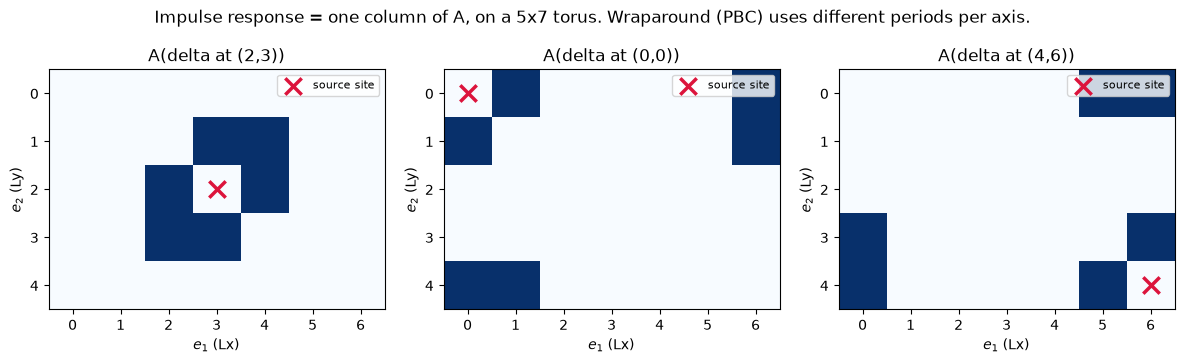

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (i, j) in zip(axes, [(2, 3), (0, 0), (4, 6)]):
    r = six_neighbor_sum(delta(Lx, Ly, i, j), p=3)
    ax.imshow(r.numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.scatter([j], [i], marker="x", s=140, c="crimson", linewidths=2.5, label="source site")
    ax.set_title(f"A(delta at ({i},{j}))")
    ax.set_xticks(range(Lx)); ax.set_yticks(range(Ly))
    ax.set_xlabel("$e_1$ (Lx)"); ax.set_ylabel("$e_2$ (Ly)")
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle(f"Impulse response = one column of A, on a {Ly}x{Lx} torus. "
             "Wraparound (PBC) uses different periods per axis.", y=1.04)
plt.tight_layout(); plt.show()

## 3. Build the full matrix $A$

Loop over all $L_x L_y$ sites, stack the impulse responses as columns. Site $k$ maps to
`(row, col) = (k // Lx, k % Lx)` — row-major flattening, so the column stride is $L_x$.

Lx=5, Ly=3, p=3: A has shape (15, 15)
Column weights (number of nonzero entries): [6]
A is symmetric (neighbour relation is mutual): True


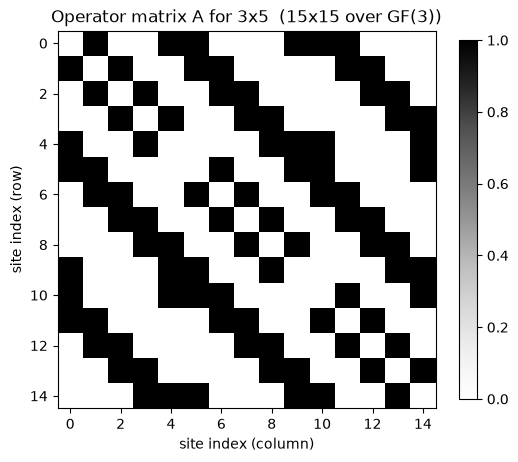

In [5]:
def build_matrix(Lx, Ly, p=2):
    '''Matrix of the six-neighbour operator on an Ly x Lx torus, over GF(p).'''
    N = Lx * Ly
    A = torch.zeros((N, N), dtype=torch.int64)
    for k in range(N):
        e = delta(Lx, Ly, k // Lx, k % Lx)
        A[:, k] = six_neighbor_sum(e, p).flatten()
    return A

Lx, Ly, p = 5, 3, 3
A = build_matrix(Lx, Ly, p)
print(f"Lx={Lx}, Ly={Ly}, p={p}: A has shape {tuple(A.shape)}")
print("Column weights (number of nonzero entries):", torch.unique((A != 0).sum(0)).tolist())
print("A is symmetric (neighbour relation is mutual):", bool((A == A.T).all()))

plt.figure(figsize=(5.5, 5))
plt.imshow(A.numpy(), cmap="Greys", interpolation="nearest")
plt.title(f"Operator matrix A for {Ly}x{Lx}  ({Lx*Ly}x{Lx*Ly} over GF({p}))")
plt.xlabel("site index (column)"); plt.ylabel("site index (row)")
plt.colorbar(shrink=0.8); plt.tight_layout(); plt.show()

On a $3\times5$ torus every column still has exactly six nonzero entries, so nothing has collapsed
yet. That changes when a side has length 2: the neighbours at $+e$ and $-e$ then land on the *same*
site and their contributions add to $2$. Over $GF(2)$ that entry vanishes outright — the operator
loses support; over $GF(3)$ it survives as a $2$. This is the first place where the modulus and the
aspect ratio genuinely interact, and it is why the thin tori $L=2$ behave differently below.

The extreme case is $L_x = L_y = 2$ over $GF(2)$, where **all three** pairs collide and $A$ becomes
the zero matrix — every configuration is an identity, $N_c = L_xL_y = 4$, in agreement with
$L_x+L_y+\gcd-2$. Over $GF(3)$ the same lattice keeps a rank-3 operator whose entries are all $2$,
leaving only $N_c = 1$ — the uniform identity of section 7.

In [6]:
print("Distinct-neighbour count per column (how many entries are nonzero), by torus shape:\n")
for (Lx, Ly) in [(5, 3), (5, 2), (2, 5), (2, 2), (3, 3)]:
    for p in (2, 3):
        A = build_matrix(Lx, Ly, p)
        w = torch.unique((A != 0).sum(0)).tolist()
        vals = torch.unique(A).tolist()
        print(f"  Lx={Lx}, Ly={Ly}, p={p}: column weights {w}, entry values present {vals}")
    print()

Distinct-neighbour count per column (how many entries are nonzero), by torus shape:

  Lx=5, Ly=3, p=2: column weights [6], entry values present [0, 1]
  Lx=5, Ly=3, p=3: column weights [6], entry values present [0, 1]

  Lx=5, Ly=2, p=2: column weights [4], entry values present [0, 1]
  Lx=5, Ly=2, p=3: column weights [5], entry values present [0, 1, 2]

  Lx=2, Ly=5, p=2: column weights [4], entry values present [0, 1]
  Lx=2, Ly=5, p=3: column weights [5], entry values present [0, 1, 2]

  Lx=2, Ly=2, p=2: column weights [0], entry values present [0]
  Lx=2, Ly=2, p=3: column weights [3], entry values present [0, 2]

  Lx=3, Ly=3, p=2: column weights [6], entry values present [0, 1]
  Lx=3, Ly=3, p=3: column weights [6], entry values present [0, 1]



## 4. Linear algebra over $GF(p)$

We need rank and nullspace **over $GF(p)$**, not over the reals. Ordinary `torch.linalg` routines
work over floats and give the wrong answer here.

Two changes from the $GF(2)$ version:

1. **Pivot normalisation.** Over $GF(2)$ the only nonzero element is $1$, so a pivot is already
   normalised. Over $GF(p)$ we must divide the pivot row by the pivot value, i.e. multiply by the
   modular inverse $a^{-1} = a^{p-2} \bmod p$ (Fermat's little theorem — valid because $p$ is prime).
2. **Elimination is subtraction, not XOR.** Over $GF(2)$, $-1 = +1$, so "add" and "subtract"
   coincide. In general we must eliminate with $R_{r'} \leftarrow R_{r'} - M_{r'c}\,R_r$ and keep the
   sign. The same applies to the nullspace back-substitution: the free-variable coefficient is
   $-R_{i f}$, which only looks like $+R_{i f}$ when $p = 2$.

In [7]:
def gfp_inv(a, p):
    '''Multiplicative inverse in GF(p) via Fermat's little theorem. p must be prime.'''
    a = int(a) % p
    if a == 0:
        raise ZeroDivisionError("0 has no inverse in GF(p)")
    return pow(a, p - 2, p)

def gfp_rref(M, p=2):
    '''Row-reduced echelon form over GF(p). Returns (R, pivot_columns).'''
    M = M.clone() % p
    rows, cols = M.shape
    pivots, r = [], 0
    for col in range(cols):
        piv = None
        for rr in range(r, rows):
            if M[rr, col] != 0:
                piv = rr
                break
        if piv is None:
            continue
        M[[r, piv]] = M[[piv, r]]
        M[r] = (M[r] * gfp_inv(M[r, col], p)) % p     # normalise pivot to 1
        for rr in range(rows):
            if rr != r and M[rr, col] != 0:
                M[rr] = (M[rr] - M[rr, col] * M[r]) % p
        pivots.append(col)
        r += 1
        if r == rows:
            break
    return M, pivots

def gfp_rank(M, p=2):
    return len(gfp_rref(M, p)[1])

def gfp_nullspace(A, p=2):
    '''Basis for {t : A t = 0} over GF(p), one vector per row.'''
    R, pivots = gfp_rref(A, p)
    cols = A.shape[1]
    free = [c for c in range(cols) if c not in pivots]
    basis = []
    for f in free:
        v = torch.zeros(cols, dtype=torch.int64)
        v[f] = 1
        for i, pc in enumerate(pivots):
            v[pc] = (-R[i, f]) % p               # note the sign: only trivial when p = 2
        basis.append(v)
    return torch.stack(basis) if basis else torch.zeros((0, cols), dtype=torch.int64)

for p in (2, 3):
    A = build_matrix(4, 4, p)
    K = gfp_nullspace(A, p)
    print(f"Lx=Ly=4, p={p} -> rank(A) = {gfp_rank(A, p)}, N_c = dim ker(A) = {K.shape[0]}")

Lx=Ly=4, p=2 -> rank(A) = 6, N_c = dim ker(A) = 10
Lx=Ly=4, p=3 -> rank(A) = 15, N_c = dim ker(A) = 1


### A vectorised rank, for the sweeps

The loop above is the readable version and stays the reference. For sweeping many lattice sizes it is
too slow: each elimination step touches one row at a time. The version below performs the whole
elimination step as a single rank-1 update, `M -= outer(M[:, col], M[r])`, which is the same
arithmetic with the Python loop over rows removed. It returns only the rank.

The assertion checks the two agree before we rely on the fast one.

In [8]:
def build_matrix_fast(Lx, Ly, p=2):
    '''Same matrix as build_matrix, all delta responses computed as one batch.'''
    N = Lx * Ly
    E = torch.eye(N, dtype=torch.int64).reshape(N, Ly, Lx)   # N stacked delta tensors
    out = torch.zeros_like(E)
    for (d2, d1) in SHIFTS:
        out = out + torch.roll(torch.roll(E, d2, 1), d1, 2)
    return (out % p).reshape(N, N).T.contiguous()            # row k of out = column k of A

def gfp_rank_fast(M, p=2):
    '''Rank over GF(p), vectorised elimination.'''
    M = M.clone() % p
    rows, cols = M.shape
    r = 0
    for col in range(cols):
        nz = (M[r:, col] != 0).nonzero()
        if nz.numel() == 0:
            continue
        piv = r + int(nz[0])
        if piv != r:
            M[[r, piv]] = M[[piv, r]]
        M[r] = (M[r] * gfp_inv(M[r, col], p)) % p
        factors = M[:, col].clone()
        factors[r] = 0
        M = (M - torch.outer(factors, M[r])) % p
        r += 1
        if r == rows:
            break
    return r

def Nc(Lx, Ly, p=2):
    '''Number of independent operator identities on an Ly x Lx torus over GF(p).'''
    return Lx * Ly - gfp_rank_fast(build_matrix_fast(Lx, Ly, p), p)

for (Lx, Ly, p) in [(4, 4, 2), (5, 3, 2), (4, 4, 3), (5, 3, 3), (6, 4, 5)]:
    A_slow, A_fast = build_matrix(Lx, Ly, p), build_matrix_fast(Lx, Ly, p)
    assert bool((A_slow == A_fast).all()), "matrix builders disagree"
    assert gfp_rank(A_slow, p) == gfp_rank_fast(A_fast, p), "rank routines disagree"
    print(f"Lx={Lx}, Ly={Ly}, p={p}: builders and rank routines agree, N_c = {Nc(Lx, Ly, p)}")

Lx=4, Ly=4, p=2: builders and rank routines agree, N_c = 10
Lx=5, Ly=3, p=2: builders and rank routines agree, N_c = 7
Lx=4, Ly=4, p=3: builders and rank routines agree, N_c = 1
Lx=5, Ly=3, p=3: builders and rank routines agree, N_c = 2
Lx=6, Ly=4, p=5: builders and rank routines agree, N_c = 2


## 5. Validation

Four independent checks, all of which must pass:

1. **Every kernel vector really is in the kernel** — verified by feeding it back through the original
   `six_neighbor_sum` roll function, not through the matrix. This closes the loop: the answer is
   checked against the code we started from.
2. **The kernel vectors are linearly independent** — their $GF(p)$ rank equals their count.
3. **Rank–nullity holds**: $\mathrm{rank}(A) + N_c = L_x L_y$.
4. **Random $GF(p)$ combinations stay in the kernel** — the kernel is a subspace, not a list of lucky
   configurations. This check has teeth only for $p > 2$, where coefficients other than $0,1$ exist.

In [9]:
def validate(Lx, Ly, p=2, n_random=8, verbose=True):
    A = build_matrix(Lx, Ly, p)
    K = gfp_nullspace(A, p)
    n = K.shape[0]

    # Check 1: feed each kernel vector back through the ORIGINAL roll operator
    viol = sum(int(six_neighbor_sum(v.reshape(Ly, Lx), p).sum() != 0) for v in K)
    in_kernel = (viol == 0)

    # Check 2: linear independence over GF(p)
    independent = (gfp_rank(K, p) == n) if n > 0 else True

    # Check 3: rank-nullity
    rank_nullity = (gfp_rank(A, p) + n == Lx * Ly)

    # Check 4: random GF(p) combinations of the basis are also in the kernel
    closed = True
    if n > 0:
        for _ in range(n_random):
            coeffs = torch.randint(0, p, (n,))
            combo = (coeffs @ K) % p
            closed &= bool((six_neighbor_sum(combo.reshape(Ly, Lx), p) == 0).all())

    if verbose:
        print(f"Lx={Lx}, Ly={Ly}, p={p}")
        print(f"  N_c                      = {n}")
        print(f"  all vectors in kernel    : {in_kernel}  ({viol} violations)")
        print(f"  linearly independent     : {independent}  (rank of basis = {gfp_rank(K, p)})")
        print(f"  rank-nullity holds       : {rank_nullity}")
        print(f"  closed under GF(p) sums  : {closed}  ({n_random} random combinations)")
    return n, (in_kernel and independent and rank_nullity and closed)

validate(5, 3, 2)
print()
validate(5, 3, 3)
print()
validate(6, 6, 3)

Lx=5, Ly=3, p=2
  N_c                      = 7
  all vectors in kernel    : True  (0 violations)
  linearly independent     : True  (rank of basis = 7)
  rank-nullity holds       : True
  closed under GF(p) sums  : True  (8 random combinations)

Lx=5, Ly=3, p=3
  N_c                      = 2
  all vectors in kernel    : True  (0 violations)
  linearly independent     : True  (rank of basis = 2)
  rank-nullity holds       : True
  closed under GF(p) sums  : True  (8 random combinations)

Lx=6, Ly=6, p=3
  N_c                      = 6
  all vectors in kernel    : True  (0 violations)
  linearly independent     : True  (rank of basis = 6)
  rank-nullity holds       : True
  closed under GF(p) sums  : True  (8 random combinations)


(6, True)

## 6. Modulus 2: the rectangular formula

For $p = 2$ the square case gave $N_c = 3L - 2$. The rectangular generalisation is

$$N_c = L_x + L_y + \gcd(L_x, L_y) - 2,$$

which reduces to $3L-2$ on the diagonal $L_x = L_y = L$, since $\gcd(L,L) = L$. The $\gcd$ is the
signature of the third lattice direction $e_1 - e_2$: a diagonal stripe closes on itself after
$\mathrm{lcm}(L_x,L_y)$ steps, leaving $\gcd(L_x,L_y)$ distinct diagonal classes.

In [10]:
Ls = range(2, 13)
grid2 = np.zeros((len(Ls), len(Ls)), dtype=int)
mismatch = []
for a, Ly in enumerate(Ls):
    for b, Lx in enumerate(Ls):
        n = Nc(Lx, Ly, 2)
        grid2[a, b] = n
        if n != Lx + Ly + gcd(Lx, Ly) - 2:
            mismatch.append((Lx, Ly, n, Lx + Ly + gcd(Lx, Ly) - 2))

print("N_c for p=2  (rows = Ly, cols = Lx, both 2..12)\n")
print("     " + "".join(f"{Lx:5d}" for Lx in Ls))
for a, Ly in enumerate(Ls):
    print(f"{Ly:3d}  " + "".join(f"{v:5d}" for v in grid2[a]))

assert not mismatch, f"formula failed for {mismatch}"
print("\nAll 121 sizes match  N_c = Lx + Ly + gcd(Lx, Ly) - 2.")
print("Diagonal (Lx = Ly = L):", [int(grid2[i, i]) for i in range(len(Ls))], "= 3L - 2.")

N_c for p=2  (rows = Ly, cols = Lx, both 2..12)

         2    3    4    5    6    7    8    9   10   11   12
  2      4    4    6    6    8    8   10   10   12   12   14
  3      4    7    6    7   10    9   10   13   12   13   16
  4      6    6   10    8   10   10   14   12   14   14   18
  5      6    7    8   13   10   11   12   13   18   15   16
  6      8   10   10   10   16   12   14   16   16   16   22
  7      8    9   10   11   12   19   14   15   16   17   18
  8     10   10   14   12   14   14   22   16   18   18   22
  9     10   13   12   13   16   15   16   25   18   19   22
 10     12   12   14   18   16   16   18   18   28   20   22
 11     12   13   14   15   16   17   18   19   20   31   22
 12     14   16   18   16   22   18   22   22   22   22   34

All 121 sizes match  N_c = Lx + Ly + gcd(Lx, Ly) - 2.
Diagonal (Lx = Ly = L): [4, 7, 10, 13, 16, 19, 22, 25, 28, 31, 34] = 3L - 2.


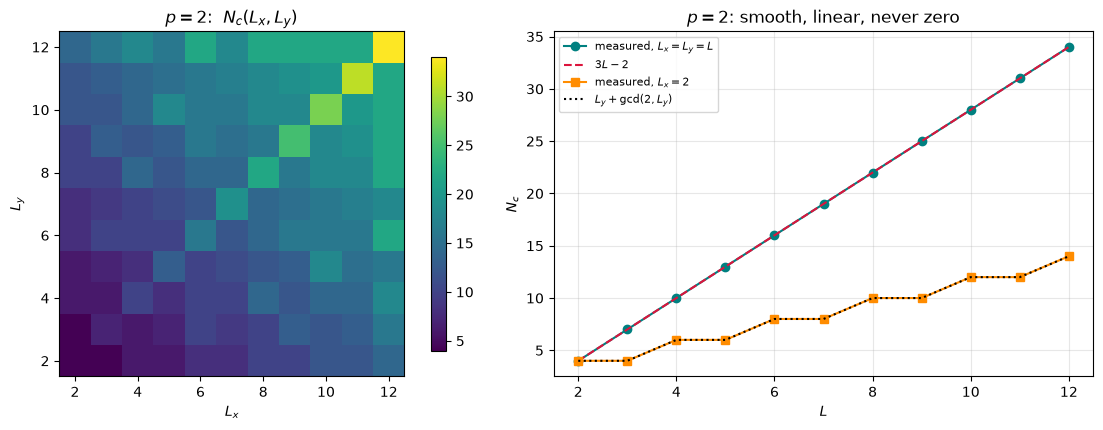

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))

im = ax[0].imshow(grid2, cmap="viridis", origin="lower",
                  extent=[1.5, 12.5, 1.5, 12.5])
ax[0].set_xlabel("$L_x$"); ax[0].set_ylabel("$L_y$")
ax[0].set_title("$p=2$:  $N_c(L_x, L_y)$")
fig.colorbar(im, ax=ax[0], shrink=0.85)

ax[1].plot(list(Ls), [grid2[i, i] for i in range(len(Ls))], "o-", color="teal",
           label="measured, $L_x=L_y=L$")
ax[1].plot(list(Ls), [3 * L - 2 for L in Ls], "--", color="crimson", label="$3L-2$")
ax[1].plot(list(Ls), [grid2[i, 0] for i in range(len(Ls))], "s-", color="darkorange",
           label="measured, $L_x=2$")
ax[1].plot(list(Ls), [2 + L + gcd(2, L) - 2 for L in Ls], ":", color="black",
           label="$L_y + \\gcd(2,L_y)$")
ax[1].set_xlabel("$L$"); ax[1].set_ylabel("$N_c$")
ax[1].set_title("$p=2$: smooth, linear, never zero")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 7. Modulus 3: the structure changes character completely

Same operator, same lattice, one different prime. $N_c$ stops being smooth in $L$ and collapses to a
sparse, number-theoretic pattern: $N_c = 1$ for most sizes, with spikes at special ones.

The $N_c \geq 1$ floor is easy to account for: the uniform configuration $t \equiv 1$ makes every site
see exactly six neighbours, and $6 \equiv 0 \pmod 3$. So the uniform state is always an operator
identity mod 3, on every torus, whatever $L_x, L_y$. The same holds mod 2 (where it is one identity
among many), and fails for every prime $p \nmid 6$ — which is why $p = 5, 7$ have $N_c = 0$ generically
rather than $1$. The next cell checks that arithmetic directly.

In [12]:
print("Uniform configuration t = 1: every site sees six neighbours, so A(1) = 6 mod p.\n")
for p in (2, 3, 5, 7):
    ones = torch.ones((5, 4), dtype=torch.int64)
    r = six_neighbor_sum(ones, p)
    print(f"  p={p}:  6 mod p = {6 % p}   ->  uniform state in kernel: {bool((r == 0).all())}")

print("\nSo p=2 and p=3 always carry the uniform identity; p=5, 7 do not.\n")
for p in (2, 3, 5, 7):
    print(f"  p={p:2d}: N_c for L=2..12 (square) = {[Nc(L, L, p) for L in range(2, 13)]}")

print("\nNote the floor: 0 for p=5,7 (no uniform identity), 1 for p=3, and never small for p=2.")
print("Note also that the SPIKES survive for p=5,7 - sparseness is not special to p=3.")

Uniform configuration t = 1: every site sees six neighbours, so A(1) = 6 mod p.

  p=2:  6 mod p = 0   ->  uniform state in kernel: True
  p=3:  6 mod p = 0   ->  uniform state in kernel: True
  p=5:  6 mod p = 1   ->  uniform state in kernel: False
  p=7:  6 mod p = 6   ->  uniform state in kernel: False

So p=2 and p=3 always carry the uniform identity; p=5, 7 do not.



  p= 2: N_c for L=2..12 (square) = [4, 7, 10, 13, 16, 19, 22, 25, 28, 31, 34]
  p= 3: N_c for L=2..12 (square) = [1, 6, 1, 1, 6, 1, 13, 18, 1, 1, 6]
  p= 5: N_c for L=2..12 (square) = [0, 6, 0, 0, 6, 0, 12, 6, 0, 0, 6]
  p= 7: N_c for L=2..12 (square) = [0, 6, 0, 0, 6, 0, 12, 6, 0, 0, 6]

Note the floor: 0 for p=5,7 (no uniform identity), 1 for p=3, and never small for p=2.
Note also that the SPIKES survive for p=5,7 - sparseness is not special to p=3.


In [13]:
grid3 = np.zeros((len(Ls), len(Ls)), dtype=int)
for a, Ly in enumerate(Ls):
    for b, Lx in enumerate(Ls):
        grid3[a, b] = Nc(Lx, Ly, 3)

print("N_c for p=3  (rows = Ly, cols = Lx, both 2..12)\n")
print("     " + "".join(f"{Lx:5d}" for Lx in Ls))
for a, Ly in enumerate(Ls):
    print(f"{Ly:3d}  " + "".join(f"{v:5d}" for v in grid3[a]))

print("\nMost entries are 1. Larger values cluster where 3 | Lx or 3 | Ly, plus isolated spikes.")

N_c for p=3  (rows = Ly, cols = Lx, both 2..12)

         2    3    4    5    6    7    8    9   10   11   12
  2      1    2    1    1    2    1    1    2    1    1    2
  3      2    6    2    2    6    2    2    6    2    2    6
  4      1    2    1    1    2    1    5    2    1    1    2
  5      1    2    1    1    2    1    1    2    1    1    2
  6      2    6    2    2    6    2    2    6    2    2    6
  7      1    2    1    1    2    1    1    2    1    1    2
  8      1    2    5    1    2    1   13    2    1    1    6
  9      2    6    2    2    6    2    2   18    2    2    6
 10      1    2    1    1    2    1    1    2    1    1    2
 11      1    2    1    1    2    1    1    2    1    1    2
 12      2    6    2    2    6    2    6    6    2    2    6

Most entries are 1. Larger values cluster where 3 | Lx or 3 | Ly, plus isolated spikes.


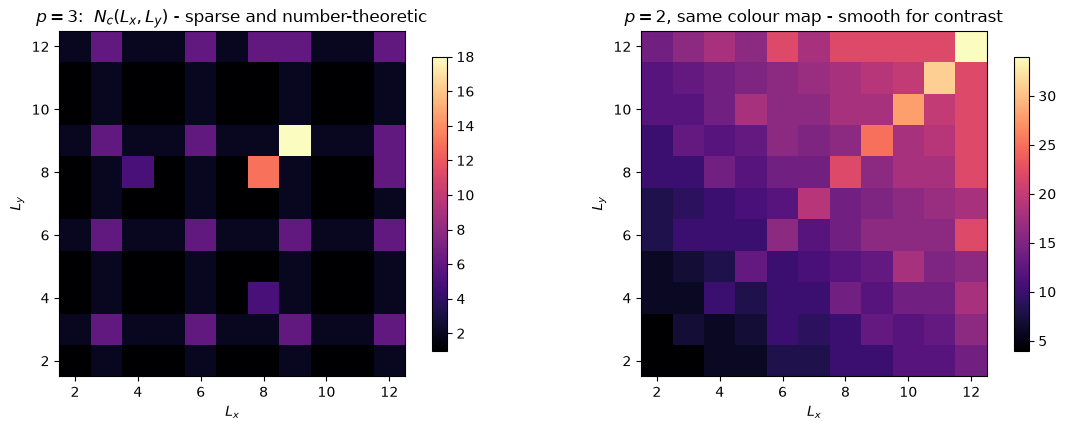

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))

im = ax[0].imshow(grid3, cmap="magma", origin="lower", extent=[1.5, 12.5, 1.5, 12.5])
ax[0].set_xlabel("$L_x$"); ax[0].set_ylabel("$L_y$")
ax[0].set_title("$p=3$:  $N_c(L_x, L_y)$ - sparse and number-theoretic")
fig.colorbar(im, ax=ax[0], shrink=0.85)

im = ax[1].imshow(grid2, cmap="magma", origin="lower", extent=[1.5, 12.5, 1.5, 12.5])
ax[1].set_xlabel("$L_x$"); ax[1].set_ylabel("$L_y$")
ax[1].set_title("$p=2$, same colour map - smooth for contrast")
fig.colorbar(im, ax=ax[1], shrink=0.85)

plt.tight_layout(); plt.show()

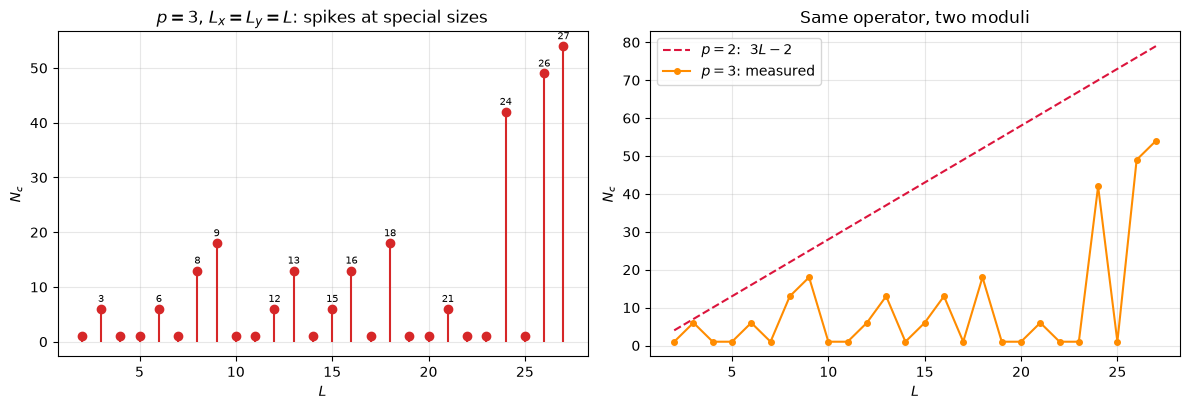

p=3 sizes with N_c > 1:
  L =   3   N_c =   6   GSD = 3^6
  L =   6   N_c =   6   GSD = 3^6
  L =   8   N_c =  13   GSD = 3^13
  L =   9   N_c =  18   GSD = 3^18
  L =  12   N_c =   6   GSD = 3^6
  L =  13   N_c =  13   GSD = 3^13
  L =  15   N_c =   6   GSD = 3^6
  L =  16   N_c =  13   GSD = 3^13
  L =  18   N_c =  18   GSD = 3^18
  L =  21   N_c =   6   GSD = 3^6
  L =  24   N_c =  42   GSD = 3^42
  L =  26   N_c =  49   GSD = 3^49
  L =  27   N_c =  54   GSD = 3^54


In [15]:
squares = list(range(2, 28))
nc3 = [Nc(L, L, 3) for L in squares]
nc2 = [3 * L - 2 for L in squares]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].stem(squares, nc3, linefmt="C3-", markerfmt="C3o", basefmt=" ")
ax[0].set_xlabel("$L$"); ax[0].set_ylabel("$N_c$")
ax[0].set_title("$p=3$, $L_x=L_y=L$: spikes at special sizes")
ax[0].grid(alpha=0.3)
for L, n in zip(squares, nc3):
    if n > 1:
        ax[0].annotate(str(L), (L, n), textcoords="offset points", xytext=(0, 5),
                       ha="center", fontsize=7)

ax[1].plot(squares, nc2, "--", color="crimson", label="$p=2$:  $3L-2$")
ax[1].plot(squares, nc3, "o-", color="darkorange", markersize=4, label="$p=3$: measured")
ax[1].set_xlabel("$L$"); ax[1].set_ylabel("$N_c$")
ax[1].set_title("Same operator, two moduli")
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print("p=3 sizes with N_c > 1:")
for L, n in zip(squares, nc3):
    if n > 1:
        print(f"  L = {L:3d}   N_c = {n:3d}   GSD = 3^{n}")

The $p=3$ spike list is exactly the kind of sparseness the original notebook was hunting for. In the
measured range $L \leq 27$ the spikes fall into two visible families: **every multiple of 3**, plus
the isolated sizes $8, 13, 16, 26$. It is *not* the $L = 2^n - 2^m$ family of the TD operator — the
relevant arithmetic here is base 3, as it must be for a $\mathbb{Z}_3$ rule — but it has the same
qualitative signature: $N_c$ (hence the GSD) depends on the *number-theoretic* properties of the
system size rather than growing smoothly with it, which is the fingerprint of fractal / type-II
fracton physics and UV/IR mixing.

The isolated family is suggestive rather than settled: $8 = 3^2-1$ and $26 = 3^3-1$, and
$13 = (3^3-1)/2$ divides $3^3-1$ — but $4$ also divides $3^2-1$ without spiking, so
"$L \mid 3^k-1$" is not by itself the condition. Item 1 of section 10 is where to pin it down.

The conclusion of the $p=2$ notebook — "whatever fractal structure the three-layer operator carries
must come from the vertical coupling, not from this isotropic in-plane term" — therefore needs the
qualifier **at $p=2$**. The in-plane term alone is already fractal-like over $\mathbb{Z}_3$.

## 8. Explicit kernel vectors

$L_x = L_y = 3$, $p = 3$ gives $N_c = 6$, so $\mathrm{GSD} = 3^6 = 729$ per plane. Each basis vector
is a configuration of exponents $t_{ij} \in \{0,1,2\}$ with $\prod_q \mathcal{O}_q^{t_q} = \mathbb{1}$
identically — an operator identity, i.e. a redundant stabilizer constraint.

Note the entries $2$: over $\mathbb{Z}_3$ an identity can use an operator *twice*, which has no
counterpart in the qubit case.

In [16]:
Lx = Ly = 3
p = 3
A3 = build_matrix(Lx, Ly, p)
K3 = gfp_nullspace(A3, p)
print(f"Lx={Lx}, Ly={Ly}, p={p}:  N_c = {K3.shape[0]},  GSD = {p}^{K3.shape[0]} = {p**K3.shape[0]}\n")

for idx, v in enumerate(K3):
    g = v.reshape(Ly, Lx)
    print(f"--- basis vector v{idx}  (weight {int((g != 0).sum())}, sum {int(g.sum())}) ---")
    print(g.numpy())
    print()

Lx=3, Ly=3, p=3:  N_c = 6,  GSD = 3^6 = 729

--- basis vector v0  (weight 2, sum 3) ---
[[0 0 2]
 [1 0 0]
 [0 0 0]]

--- basis vector v1  (weight 2, sum 3) ---
[[2 0 0]
 [0 1 0]
 [0 0 0]]

--- basis vector v2  (weight 2, sum 3) ---
[[0 2 0]
 [0 0 1]
 [0 0 0]]

--- basis vector v3  (weight 2, sum 3) ---
[[0 2 0]
 [0 0 0]
 [1 0 0]]

--- basis vector v4  (weight 2, sum 3) ---
[[0 0 2]
 [0 0 0]
 [0 1 0]]

--- basis vector v5  (weight 2, sum 3) ---
[[2 0 0]
 [0 0 0]
 [0 0 1]]



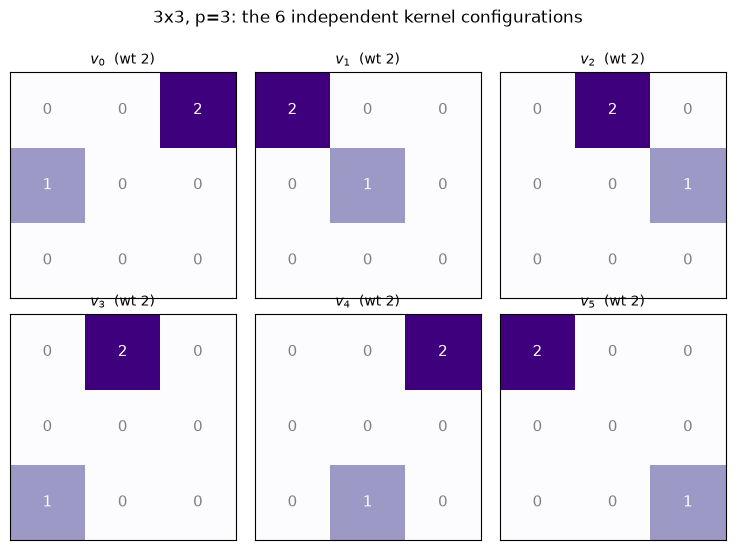

In [ ]:
ncols = 3
nrows = int(np.ceil(K3.shape[0] / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 2.7 * nrows))
axes = np.atleast_1d(axes).ravel()

for idx, ax in enumerate(axes):
    if idx < K3.shape[0]:
        g = K3[idx].reshape(Ly, Lx).numpy()
        ax.imshow(g, cmap="Purples", vmin=0, vmax=p - 1)
        for i in range(Ly):
            for j in range(Lx):
                ax.text(j, i, g[i, j], ha="center", va="center",
                        color="white" if g[i, j] else "gray", fontsize=11)
        ax.set_title(f"$v_{{{idx}}}$  (wt {int((g != 0).sum())})", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    else:
        ax.axis("off")

fig.suptitle(f"{Ly}x{Lx}, p={p}: the {K3.shape[0]} independent kernel configurations", y=1.01)
plt.show()

### Verify each one individually against the original roll code

The strongest check: take each basis vector, push it through the *exact* six-roll expression we
started with, and confirm the output grid is identically zero mod $p$.

In [18]:
print("Per-vector verification against six_neighbor_sum (the original roll code):\n")
for idx, v in enumerate(K3):
    r = six_neighbor_sum(v.reshape(Ly, Lx), p)
    print(f"  v{idx}:  A(v) all zero -> {bool((r == 0).all())}   (sum of residual = {int(r.sum())})")

print("\nIndependence spot-check (no vector is a GF(p) combination of the others):")
for idx in range(K3.shape[0]):
    others = torch.cat([K3[:idx], K3[idx + 1:]], dim=0)
    stacked = torch.cat([others, K3[idx:idx + 1]], dim=0)
    print(f"  v{idx}: rank(others)={gfp_rank(others, p)}, "
          f"rank(others + v{idx})={gfp_rank(stacked, p)}  -> independent: "
          f"{gfp_rank(stacked, p) > gfp_rank(others, p)}")

print("\nRandom GF(p) combinations must also lie in the kernel:")
for trial in range(6):
    coeffs = torch.randint(0, p, (K3.shape[0],))
    combo = (coeffs @ K3) % p
    r = six_neighbor_sum(combo.reshape(Ly, Lx), p)
    print(f"  trial {trial}: coeffs={coeffs.tolist()}  ->  in kernel: {bool((r == 0).all())}")

print(f"\nTotal configurations in the kernel: {p}^{K3.shape[0]} = {p**K3.shape[0]}")

Per-vector verification against six_neighbor_sum (the original roll code):

  v0:  A(v) all zero -> True   (sum of residual = 0)
  v1:  A(v) all zero -> True   (sum of residual = 0)
  v2:  A(v) all zero -> True   (sum of residual = 0)
  v3:  A(v) all zero -> True   (sum of residual = 0)
  v4:  A(v) all zero -> True   (sum of residual = 0)
  v5:  A(v) all zero -> True   (sum of residual = 0)

Independence spot-check (no vector is a GF(p) combination of the others):
  v0: rank(others)=5, rank(others + v0)=6  -> independent: True
  v1: rank(others)=5, rank(others + v1)=6  -> independent: True
  v2: rank(others)=5, rank(others + v2)=6  -> independent: True
  v3: rank(others)=5, rank(others + v3)=6  -> independent: True
  v4: rank(others)=5, rank(others + v4)=6  -> independent: True
  v5: rank(others)=5, rank(others + v5)=6  -> independent: True

Random GF(p) combinations must also lie in the kernel:
  trial 0: coeffs=[1, 2, 2, 2, 1, 1]  ->  in kernel: True
  trial 1: coeffs=[1, 1, 0, 2, 2,

## 9. Why the modulus changes everything: the multiplier polynomial

Write the operator in the polynomial (Laurent) representation, $x \leftrightarrow e_1$,
$y \leftrightarrow e_2$:

$$P(x,y) = x + x^{-1} + y + y^{-1} + x^{-1}y + xy^{-1},
\qquad
xy\,P(x,y) = x^2 + y^2 + x + y + x^2y + xy^2 .$$

The same polynomial factors differently depending on the prime:

$$
\begin{aligned}
p = 2:&\quad xyP = (1+x)(1+y)(x+y) \\
p = 3:&\quad xyP = (1 + x + y)(xy + x + y)
\end{aligned}
$$

*(Check for $p=3$: expanding gives $x^2y + xy^2 + x^2 + y^2 + 3xy + x + y$, and $3xy \equiv 0$.)*

Over $GF(2)$ the three factors are the three lattice directions — $1+x$ gives stripes constant along
$e_1$, $1+y$ stripes constant along $e_2$, and $x+y$ stripes constant along the diagonal $e_1-e_2$.
Each family is closed on the torus, and the diagonal one closes into $\gcd(L_x,L_y)$ classes. Three
stripe families of sizes $L_x$, $L_y$, $\gcd(L_x,L_y)$, minus the two overcounted overlaps, is
exactly the measured $L_x + L_y + \gcd(L_x,L_y) - 2$. (The count is a sketch, not a proof — the
overlap structure is what section 10 item 1 asks to nail down.)

Over $GF(3)$ the factorisation is into two factors neither of which is a product of one-variable
pieces. There are no stripes to count: the kernel dimension instead becomes a question about the
order of the roots of $1+x+y$ and $xy+x+y$ in extensions of $GF(3)$, i.e. about the multiplicative
structure of $L_x, L_y$ relative to powers of 3. That is the mechanism behind the sparseness.

The next cell verifies the two factorisations symbolically rather than trusting the algebra above.

In [19]:
def poly_mul(a, b, p):
    '''Multiply dicts {(i,j): coeff} representing polynomials in x, y over GF(p).'''
    out = {}
    for (i1, j1), c1 in a.items():
        for (i2, j2), c2 in b.items():
            k = (i1 + i2, j1 + j2)
            out[k] = (out.get(k, 0) + c1 * c2) % p
    return {k: v for k, v in out.items() if v % p}

# xy * P(x, y) = x^2 + y^2 + x + y + x^2 y + x y^2
target = {(2, 0): 1, (0, 2): 1, (1, 0): 1, (0, 1): 1, (2, 1): 1, (1, 2): 1}

factorisations = {
    2: [{(0, 0): 1, (1, 0): 1}, {(0, 0): 1, (0, 1): 1}, {(1, 0): 1, (0, 1): 1}],   # (1+x)(1+y)(x+y)
    3: [{(0, 0): 1, (1, 0): 1, (0, 1): 1}, {(1, 1): 1, (1, 0): 1, (0, 1): 1}],     # (1+x+y)(xy+x+y)
}

for p, factors in factorisations.items():
    prod = {(0, 0): 1}
    for f in factors:
        prod = poly_mul(prod, f, p)
    tgt = {k: v % p for k, v in target.items() if v % p}
    print(f"p={p}: factorisation reproduces xy*P :", prod == tgt)
    print(f"       product = {dict(sorted(prod.items()))}")
    print(f"       xy*P    = {dict(sorted(tgt.items()))}\n")

p=2: factorisation reproduces xy*P : True
       product = {(0, 1): 1, (0, 2): 1, (1, 0): 1, (1, 2): 1, (2, 0): 1, (2, 1): 1}
       xy*P    = {(0, 1): 1, (0, 2): 1, (1, 0): 1, (1, 2): 1, (2, 0): 1, (2, 1): 1}

p=3: factorisation reproduces xy*P : True
       product = {(0, 1): 1, (0, 2): 1, (1, 0): 1, (1, 2): 1, (2, 0): 1, (2, 1): 1}
       xy*P    = {(0, 1): 1, (0, 2): 1, (1, 0): 1, (1, 2): 1, (2, 0): 1, (2, 1): 1}



## 10. Where to go next

1. **Pin down the $p=3$ spike condition.** The measured sizes with $N_c > 1$ are the data; the
   polynomial factorisation above is the tool. Working out when $1+x+y$ and $xy+x+y$ acquire common
   roots on the torus $x^{L_x} = y^{L_y} = 1$ should give the arithmetic condition in closed form,
   the base-3 analogue of the TD operator's $L = 2^n - 2^m$.

2. **Sweep more primes.** The $p$ scan in section 7 already shows two separate effects: the *floor*
   is set by whether $p \mid 6$ (so $p=2,3$ carry the uniform identity and $p \geq 5$ do not), while
   the *spikes* survive at $p = 5, 7$ as well. Sparseness is therefore generic to $p \geq 3$, and
   $p=2$ is the exceptional case, not $p=3$. Worth extending: does the spike *set* depend on $p$, or
   only the spike heights? The $p=5$ and $p=7$ columns are identical over $L \leq 12$, which suggests
   the set may not.

3. **Add the vertical direction.** Extend `six_neighbor_sum` with a third `torch.roll` along $z$
   (tensor shape `(Lz, Ly, Lx)`) to encode the three-layer structure, rebuild the matrix, and see how
   the in-plane $p=3$ sparseness interacts with the inter-layer coupling.

4. **Performance.** `gfp_rank_fast` is $O(N^3)$ with $N = L_x L_y$, so $L \approx 30$ is roughly the
   practical ceiling. The operator is translation-invariant, so a Fourier / transfer-matrix approach
   would reduce the problem to $L_x$ blocks of size $L_y$ and push this much further.